# Carbon-Cycle Fisher Information Spectrum and Tempered SMC Model Selection

Decadal tree-ring $\Delta^{14}\mathrm{C}$ time series probe a diffusive Laplace transform of carbon-box residence times whose singular values decay exponentially (the carbon-cycle counterpart of McWhirter & Pike 1978 and Langker et al. 2026). This notebook uses `cbm_fisher_spectrum` to quantify how many carbon-cycle parameter combinations the 774 CE dataset actually constrains in `Brehm21` and `EffectiveCBM(K=2, 3, 4)`, then runs `BlackJAX` adaptive tempered SMC (`sample_smc`) across reservoir counts $K = 1, 2, 3, 4$ to verify Occam saturation of the Bayesian log-evidence $\ln \widehat{Z}_K$.

In [1]:
import math
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import ticktack as tt

dataset = tt.load_bundled_event("775CE")
spike0 = tt.MiyakeSpike(t_start=774.5, duration=0.35, fluence=6.5, profile="boxcar")
psi0 = {"spike": spike0, "offsets": jnp.zeros(dataset.n_series)}
fwd = lambda cbm_v, psi: tt.RadiocarbonModel(cbm_v, tt.SteadyProduction() + psi["spike"]).predict_d14c(dataset, offsets=psi["offsets"])

cbm_brehm = tt.load_preset("Brehm21", kind="balanced")
sd_brehm = jnp.append(jnp.full(cbm_brehm.log_rates_free.size, 0.35), jnp.inf)
spec_brehm = tt.cbm_fisher_spectrum(fwd, cbm_brehm, dataset.sigma_flat, psi_nuisance=psi0, prior_cbm_sd=sd_brehm)
eff_specs = {k: tt.cbm_fisher_spectrum(fwd, tt.EffectiveCBM(K=k), dataset.sigma_flat, psi_nuisance=psi0, prior_cbm_sd=0.35) for k in (2, 3, 4)}
lines = [f"Brehm21 (52 free rates): d_eff = {float(spec_brehm.d_eff):.2f}, I = {float(spec_brehm.info_bits):.2f} bits"]
lines += [f"EffectiveCBM(K={k}, {2*k-2} params): d_eff = {float(s.d_eff):.2f}, I = {float(s.info_bits):.2f} bits" for k, s in eff_specs.items()]
print("\n".join(lines))


Brehm21 (52 free rates): d_eff = 3.18, I = 6.61 bits
EffectiveCBM(K=2, 2 params): d_eff = 1.05, I = 2.12 bits
EffectiveCBM(K=3, 4 params): d_eff = 1.65, I = 3.45 bits
EffectiveCBM(K=4, 6 params): d_eff = 1.56, I = 3.16 bits


Even though `Brehm21` carries 52 independent flow-balanced log transfer rates (with global total carbon mass projected out analytically as a zero-Fisher gauge coordinate), Schur-complement marginalization over the spike and per-series offsets reveals rapid exponential decay of the prior-whitened eigenvalues $\mu_k$: only a few collective exchange combinations exceed the unit signal-to-prior threshold $\mu_k = 1$.

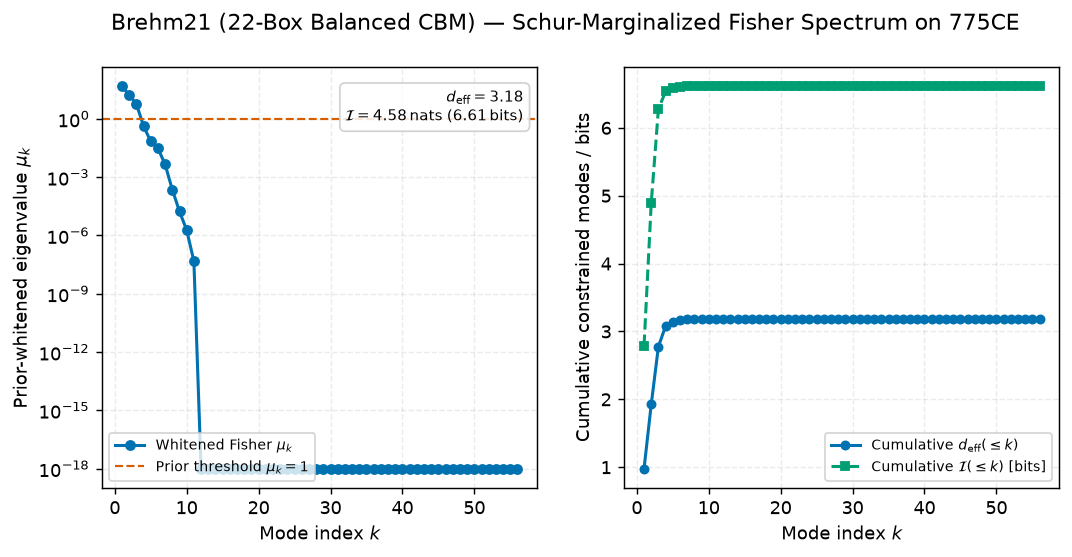

In [2]:
fig, axes = tt.plot_fisher_spectrum(
    spec_brehm,
    title="Brehm21 (22-Box Balanced CBM) — Schur-Marginalized Fisher Spectrum on 775CE",
)
plt.show()


To test Bayesian model selection directly, we compare a 1-box open atmosphere (`OpenCBM`, $K = 1$) against gauge-free mammillary `EffectiveCBM(K)` models for $K = 2, 3, 4$, placing Gaussian priors on all dynamic CBM exchange log-rates and ordered sink residence-time parameters alongside the spike onset and fluence. `sample_smc` uses multinomial resampling and the Lee & Whiteley (2018) lineage estimator so every $\ln \widehat{Z}_K$ carries a calibrated Monte Carlo standard error $\sigma_{\ln Z}$.

In [3]:
cfg_smc = tt.LinearMarginalConfig(offset_mode="hierarchical", marginalize_solar=False, marginalize_gp=False)
cbm_k1 = tt.OpenCBM(tt.Topology(["Troposphere"], [], []), jnp.zeros(0), math.log(501.5), jnp.array([math.log(0.088)]), open_box_indices=[0])
cbms = {1: cbm_k1, 2: tt.EffectiveCBM(K=2), 3: tt.EffectiveCBM(K=3), 4: tt.EffectiveCBM(K=4)}
smc_results = {}
for k, cbm_k in cbms.items():
    m_k = tt.RadiocarbonModel(cbm_k, tt.ProductionSum(steady=tt.SteadyProduction(), spike=spike0))
    cbm_specs = ([tt.ParamSpec("cbm.log_sink_rates", "identity", prior_mean=float(cbm_k.log_sink_rates[0]), prior_sd=0.35)] if k == 1 else [
        tt.ParamSpec("cbm.log_k_strat_to_trop", "identity", prior_mean=float(cbm_k.log_k_strat_to_trop), prior_sd=0.35),
        tt.ParamSpec("cbm.log_k_trop_to_strat", "identity", prior_mean=float(cbm_k.log_k_trop_to_strat), prior_sd=0.35),
        tt.ParamSpec("cbm.log_k_trop_to_sinks", "identity", prior_mean=cbm_k.log_k_trop_to_sinks, prior_sd=0.35),
        tt.ParamSpec("cbm.sink_tau_params", "identity", prior_mean=cbm_k.sink_tau_params, prior_sd=0.50),
    ])
    sp_specs = [tt.ParamSpec("production.spike.t_start", "identity", prior_mean=774.5, prior_sd=0.4), tt.ParamSpec("production.spike.fluence", "exp", prior_mean=math.log(6.5), prior_sd=0.5)]
    smc_results[k] = tt.sample_smc(m_k, dataset, tt.ParameterSpace(m_k, cbm_specs + sp_specs), cfg_smc, num_particles=120, num_mcmc_steps=4, rng_key=jax.random.PRNGKey(10 + k))
best_lnz = max(float(r.log_evidence) for r in smc_results.values())
print("\n".join(f"K = {k} ({r.particles.shape[1]} params): ln Z = {float(r.log_evidence):.2f} +/- {float(r.log_evidence_err):.2f} (Delta ln Z = {float(r.log_evidence) - best_lnz:+.2f})" for k, r in smc_results.items()))


K = 1 (3 params): ln Z = -808.82 +/- 0.61 (Delta ln Z = -53.25)
K = 2 (4 params): ln Z = -793.28 +/- 0.24 (Delta ln Z = -37.71)
K = 3 (6 params): ln Z = -755.57 +/- 0.44 (Delta ln Z = +0.00)
K = 4 (8 params): ln Z = -756.05 +/- 0.56 (Delta ln Z = -0.48)


Plotting $\ln \widehat{Z}_K \pm \sigma_{\ln Z}$ alongside the effective constrained dimensionality $d_{\mathrm{eff}}(K)$ illustrates how adding a stratosphere and a decadal biosphere/mixed-layer sink ($K = 3$) substantially improves the fit to the 774 CE rise and post-spike relaxation, whereas additional unconstrained sinks ($K = 4$) yield no further evidence gain once $2K - 2$ exceeds $d_{\mathrm{eff}}$.

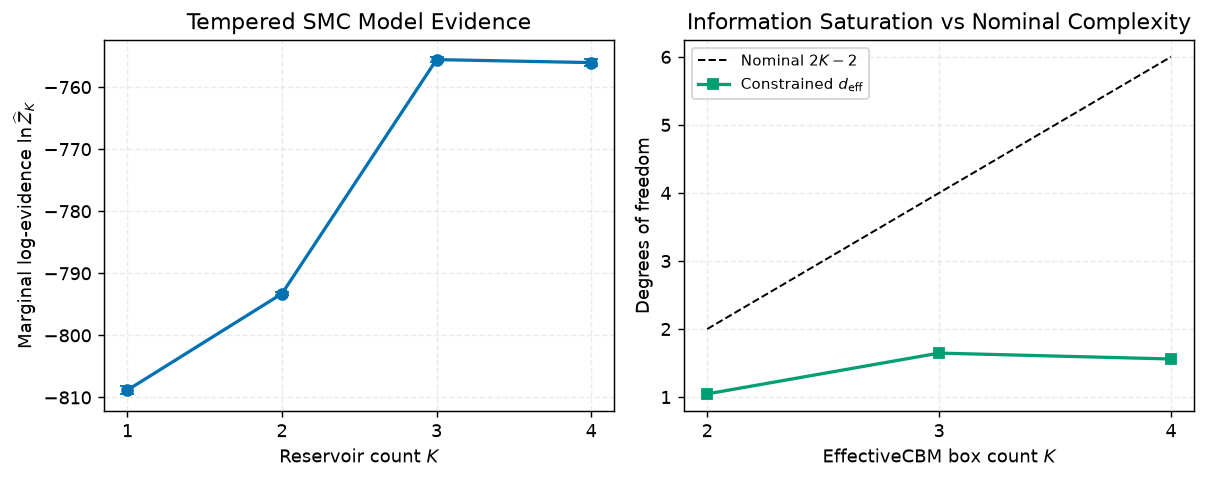

In [4]:
ks = np.array([1, 2, 3, 4])
lnz = np.array([float(smc_results[k].log_evidence) for k in ks])
lnz_err = np.array([float(smc_results[k].log_evidence_err) for k in ks])
deffs = np.array([float(eff_specs[k].d_eff) for k in (2, 3, 4)])

fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.8))
axes[0].errorbar(ks, lnz, yerr=lnz_err, fmt="o-", color="#0072B2", lw=1.8, capsize=4)
axes[0].set(xticks=ks, xlabel="Reservoir count $K$", ylabel=r"Marginal log-evidence $\ln \widehat{Z}_K$", title="Tempered SMC Model Evidence")
axes[0].grid(True, alpha=0.25, ls="--")
axes[1].plot([2, 3, 4], [2, 4, 6], "k--", lw=1.1, label="Nominal $2K - 2$")
axes[1].plot([2, 3, 4], deffs, "s-", color="#009E73", lw=1.8, label=r"Constrained $d_{\mathrm{eff}}$")
axes[1].set(xticks=[2, 3, 4], xlabel="EffectiveCBM box count $K$", ylabel="Degrees of freedom", title="Information Saturation vs Nominal Complexity")
axes[1].legend(frameon=True, fontsize=8.5)
axes[1].grid(True, alpha=0.25, ls="--")
fig.tight_layout()
plt.show()


Together, `cbm_fisher_spectrum` and `sample_smc` establish why decadal radiocarbon datasets identify two to three effective carbon-cycle relaxation modes (`EffectiveCBM` with $K = 3$), providing rigorous uncertainty propagation without arbitrary parameter fixing.